In [1]:
!pip3 install scanpy==1.9.3

In [2]:
!pip3 install scib-metrics==0.5.1 #bug in version from requirements

In [3]:
!pip3 install leidenalg==0.10.1

In [4]:
!pip3 install louvain==0.8.1

## Imports

In [1]:
import scanpy as sc
import numpy as np
import pandas as pd
import metrics_lib as metrics
import os

/usr/local/lib/python3.10/dist-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
2024-04-05 03:26:05.931254: E external/local_xla/xla/stream_executor/cuda/cuda_dnn.cc:9373] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
2024-04-05 03:26:05.931327: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:607] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
2024-04-05 03:26:05.934311: E external/local_xla/xla/stream_executor/cuda/cuda_blas.cc:1534] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered


## Set global variables

In [2]:
DATA_DIR = os.path.abspath(os.path.join(os.getcwd(), '..', 'Data'))
RESULT_DIR = os.path.abspath(os.path.join(os.getcwd(), '..', 'Results'))

In [3]:
#set variables to subset data
dataset="Sheppard_2020"
condition="IPF"
mode="sample"

## load and prep Data

### load and prep embedding 

In [4]:
adata = sc.read_h5ad(f"{DATA_DIR}/Mapping/sheppard_sample.h5ad")

In [5]:
#set the "dataset" variable correctly

In [6]:
adata.obs.dataset = adata.obs.dataset.astype(str)
adata.obs.loc[adata.obs.study == "Sheppard2020","dataset"] ="Sheppard_2020"
adata.obs.dataset = adata.obs.dataset.astype("category")

In [7]:
# make X to obsm
adata.obsm["X_scanvi"] = adata.X

In [8]:
#subset to dataset
adata=adata[(adata.obs.dataset == dataset )|(adata.obs['core_or_extension']=="core") ].copy()

In [9]:
adata.obs.loc[~(adata.obs.dataset == dataset), "condition"]="NML"

In [10]:
#subset to condition
adata=adata[(adata.obs.condition == condition )|(adata.obs['core_or_extension']=="core") ].copy()


### load and prep query_counts

In [11]:
adata_query=sc.read_h5ad(f"{DATA_DIR}/Query_counts/subsetted_HLCA.h5ad")

In [12]:
del adata_query.obsm["X_scanvi_emb"] #not the one we are working with

In [13]:
adata_query

AnnData object with n_obs × n_vars = 209101 × 56295
    obs: 'suspension_type', 'donor_id', 'is_primary_data', 'assay_ontology_term_id', 'cell_type_ontology_term_id', 'development_stage_ontology_term_id', 'disease_ontology_term_id', 'self_reported_ethnicity_ontology_term_id', 'tissue_ontology_term_id', 'organism_ontology_term_id', 'sex_ontology_term_id', "3'_or_5'", 'BMI', 'age_or_mean_of_age_range', 'age_range', 'anatomical_region_ccf_score', 'ann_coarse_for_GWAS_and_modeling', 'ann_finest_level', 'ann_level_1', 'ann_level_2', 'ann_level_3', 'ann_level_4', 'ann_level_5', 'cause_of_death', 'core_or_extension', 'dataset', 'fresh_or_frozen', 'log10_total_counts', 'lung_condition', 'mixed_ancestry', 'original_ann_level_1', 'original_ann_level_2', 'original_ann_level_3', 'original_ann_level_4', 'original_ann_level_5', 'original_ann_nonharmonized', 'reannotation_type', 'sample', 'scanvi_label', 'sequencing_platform', 'smoking_status', 'study', 'subject_type', 'tissue_coarse_unharmonized', '

In [14]:
#set obs

In [15]:
adata[adata.obs.core_or_extension=="extension"].obs.index

Index(['TGAGCATGTTGCCTCT_IPF3', 'AACCATGGTGGTCCGT_IPF3',
       'TGCCAAATCTCAAACG_IPF2', 'CGTGTAATCTACTCAT_IPF3',
       'CGTAGCGAGACTTTCG_IPF3', 'CATGCCTCACATGTGT_IPF2',
       'ATCATCTGTACCGTAT_IPF3', 'AACTGGTTCTGTTTGT_IPF3',
       'ACGGGCTCATCCGGGT_IPF3', 'CCTCTGAGTCTGCCAG_IPF1',
       ...
       'GCCTCTACAACGCACC_IPF3', 'GTTCATTGTCTGCAAT_IPF3',
       'CATATGGTCTGCCAGG_IPF2', 'GTATCTTCACCCAGTG_IPF3',
       'GGGACCTGTAATTGGA_IPF3', 'TGCACCTTCGTACCGG_IPF2',
       'CTGATCCGTTAAGGGC_IPF3', 'AGCAGCCAGTACGCCC_IPF3',
       'TCAGCTCTCTAGCACA_IPF3', 'GTCATTTTCTTAGAGC_IPF3'],
      dtype='object', length=33817)

In [16]:
#new index (remove tsukui to synchronize data)
adata_query.obs.index= [i.strip("_tsukui") for i in adata_query.obs.index]

In [17]:
#subset to only query of interest (dataset and condition)
adata_query =  adata_query[list(set(adata_query.obs.index).intersection(set(adata.obs.index)))]

In [18]:
adata_query.obs = adata.obs.loc[list(set(adata_query.obs.index).intersection(set(adata.obs.index)))]

In [19]:
adata_query.obsm["X_scanvi"] = adata[list(set(adata_query.obs.index).intersection(set(adata.obs.index)))].X

## run metrics

In [20]:
#set some variables for running metrics
obsm_emb_key = 'X_scanvi'
donor_key= 'donor_id'
dataset_key="dataset"
sample_key="sample"
original_emb_key=None
batch_key = "sample"

In [21]:
scib_results = metrics.calculate_scib_metrics(adata, obsm_emb_key, batch_key, dataset_key, sample_key, dry_run=False)

Time to complete scib neighbors calculation: 615.343 s
Time to complete lisi_batch: 7.420 s
Time to complete kbet_batch: 2.256 s


In [22]:
symphony_results = metrics.calculate_symphony_metrics(adata, adata_query, obsm_emb_key, donor_key, dataset_key, sample_key, dry_run=False)

Time to complete symphony metrics neighbors calculation: 5.696 s
Time to complete lisi_query_donor: 1.034 s
Time to complete wiq_knn_corr: 204.977 s


In [23]:
other_results = metrics.calculate_other_metrics(adata, adata_query, obsm_emb_key, dataset_key, sample_key, dry_run=False)

/dss/dsshome1/0F/di35qon/Metrics/Code/metrics_lib.py:188: RuntimeWarning: divide by zero encountered in log
  return np.nansum(px * np.log(px), axis=1)  # calculate label entropy for each cell
/dss/dsshome1/0F/di35qon/Metrics/Code/metrics_lib.py:188: RuntimeWarning: invalid value encountered in multiply
  return np.nansum(px * np.log(px), axis=1)  # calculate label entropy for each cell
/dss/dsshome1/0F/di35qon/Metrics/Code/metrics_lib.py:188: RuntimeWarning: divide by zero encountered in log
  return np.nansum(px * np.log(px), axis=1)  # calculate label entropy for each cell
/dss/dsshome1/0F/di35qon/Metrics/Code/metrics_lib.py:188: RuntimeWarning: invalid value encountered in multiply
  return np.nansum(px * np.log(px), axis=1)  # calculate label entropy for each cell


Time to complete cluster_preservation_score: 106.550 s


In [24]:
#save results
adata.obs["lisi_batch"] = scib_results["lisi_batch"]["per_cell"]
adata.obs["kbet_batch"] = scib_results["kbet_batch"]["per_cell"]
adata.obs['lisi_query_donor'] = symphony_results['lisi_query_donor']["per_cell"]
adata.obs['wiq_knn_corr'] = symphony_results['wiq_knn_corr']["per_cell"]
adata.obs['cluster_preservation_score']=other_results['cluster_preservation_score']["per_cell"]

In [25]:
adata.obs[["lisi_batch","kbet_batch",'lisi_query_donor','wiq_knn_corr','cluster_preservation_score']].dropna()

,lisi_batch,kbet_batch,lisi_query_donor,wiq_knn_corr,cluster_preservation_score
TGAGCATGTTGCCTCT_IPF3,1.651799e-03,0.0,-7.050467e-12,0.287285,0.706348
AACCATGGTGGTCCGT_IPF3,1.402462e-09,0.0,-7.050467e-12,0.242172,5.000000
TGCCAAATCTCAAACG_IPF2,6.428334e-03,0.0,1.057570e-11,0.276700,0.000000
CGTGTAATCTACTCAT_IPF3,7.955886e-03,0.0,0.000000e+00,0.224970,1.399314
CGTAGCGAGACTTTCG_IPF3,7.798013e-04,0.0,0.000000e+00,0.199694,1.535435
...,...,...,...,...,...
TGCACCTTCGTACCGG_IPF2,1.569507e-02,0.0,3.525233e-12,0.323586,5.000000
CTGATCCGTTAAGGGC_IPF3,1.916720e-03,0.0,0.000000e+00,0.063073,5.000000
AGCAGCCAGTACGCCC_IPF3,7.058242e-05,0.0,0.000000e+00,0.108697,2.332678
TCAGCTCTCTAGCACA_IPF3,6.778072e-04,0.0,-1.410093e-11,0.012801,1.621120


In [26]:
adata.obs[["lisi_batch","kbet_batch",'lisi_query_donor','wiq_knn_corr','cluster_preservation_score']].to_csv(f'{RESULT_DIR}/metrics_{mode}_{dataset}_{condition}.csv')

## Visualize 

Run Load and prep embeddings and set global variables first

In [27]:
adata.obs[["lisi_batch","kbet_batch",'lisi_query_donor','wiq_knn_corr','cluster_preservation_score']] = pd.read_csv(f'{RESULT_DIR}/metrics_{mode}_{dataset}_{condition}.csv',index_col = "Unnamed: 0")

In [28]:
sc.pp.neighbors(adata,n_neighbors=50)

In [29]:
sc.tl.umap(adata)

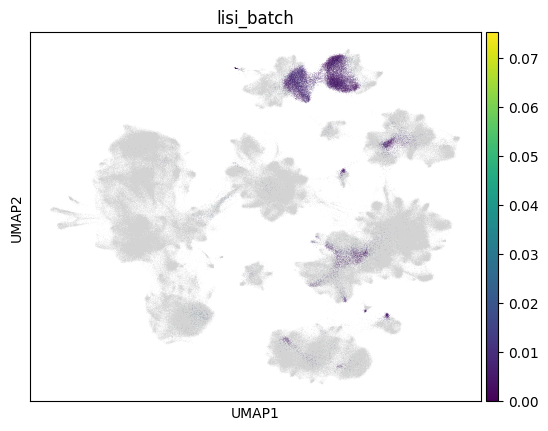

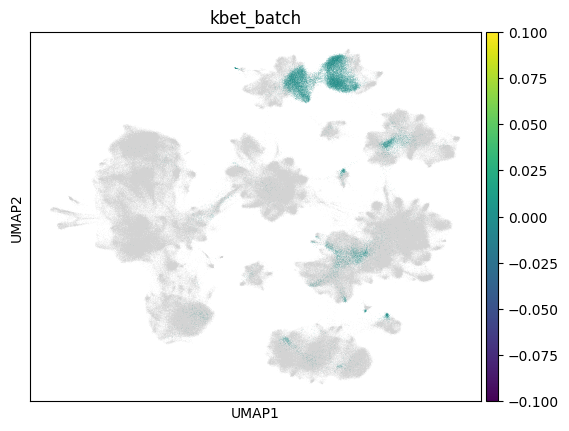

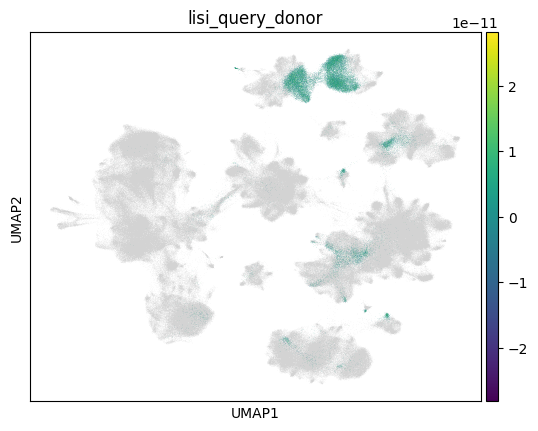

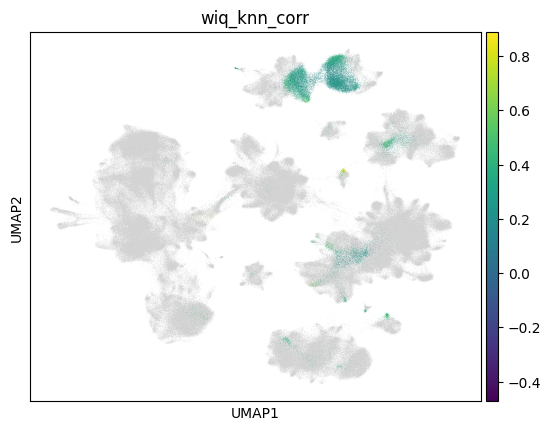

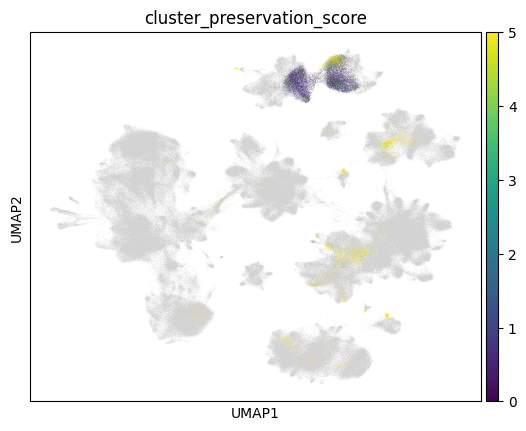

In [30]:
for metric in ["lisi_batch","kbet_batch",'lisi_query_donor','wiq_knn_corr','cluster_preservation_score']:
    adata.obs.loc[adata.obs.core_or_extension=="core",metric]=np.nan
    sc.pl.umap(adata,color=metric)